# 08 — The eight prosodic target dimensions

**Stage question.** How is each of the eight dimensions computed from the stored tracks, how many turns can carry each, and do the four blocks hold together?

| | |
|---|---|
| **Purpose** | Compute the eight registered dimensions per turn from the frame tracks and timed words; report missingness per dimension and its reasons; describe distributions and within-block correlations (exploratory). |
| **Input** | Frame tracks (notebook 03), raw transcripts, `turns.parquet`. |
| **Processing** | Per turn: inter-pausal units from words → speech frames → pitch, energy and timing dimensions → failure reasons. No audio is fetched. |
| **Output** | `data/processed/turn_prosody__<stage>__m<signature>.parquet`; `results/prosody/` tables; figures. |
| **Scientific assumptions** | Definitions of PREREGISTRATION §4; operational details in `src/settings.py`. |
| **Failure modes** | Turns that cannot carry a dimension (dropped with a reason, never imputed); a measurement setting changed after a result (prevented: the signature tags every output). |
| **What to look at** | Missingness per dimension, the boundary-slope loss, and the block correlations. |

**Terms used in this notebook.**

- **Inter-pausal unit (IPU)** — a stretch of one speaker's words without a silence of 50 ms or more.
- **Articulation rate** — syllables per second of speaking time, pauses excluded.
- **Pause ratio** — internal pause time divided by turn duration.
- **Boundary slope** — how fast log-F0 rises or falls over the last 300 ms of the turn.

> **Before running.** Overlap handling, the pitch range and syllable counting are set in `src/settings.py`. The pitch range is the fixed 75–500 Hz range the tracks were extracted with (PREREGISTRATION §4 fixes floor and ceiling in configuration).

In [4]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
runtime        colab   python 3.13.16   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   11.8 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint e1a10dc2c7145664
artifacts      manifest=True, metadata=True, transcripts=True, turns=True, audio_pass_sessions=293, channel_qc=True


**Runtime check.** The cell above prints free disk, memory, CPU, GPU, the code fingerprint and which artifacts already exist. The fingerprint identifies the exact source and configuration that ran and is written into every run record.

In [5]:
STAGE = 'sample'
STEPS = ['prosody_targets']

## Settings

The method settings come from `src/settings.py` (class `Settings`).

In [6]:
from src.settings import Settings
SETTINGS = Settings()

## 1. Compute the eight dimensions

In [7]:
from src.paths import paths
from src.experiments.stages import prosody_targets, tag
from src.features.prosody import droppage_by_dimension
P = paths()
pro = prosody_targets(P, STAGE, SETTINGS)
print('output tag:', tag(STAGE, SETTINGS))
OUT = P.results / 'prosody'
OUT.mkdir(parents=True, exist_ok=True)
drop = droppage_by_dimension(pro)
drop.to_csv(OUT / f'droppage_by_dimension_{tag(STAGE, SETTINGS)}.csv', index=False)
drop

output tag: sample__m55a87f6ee7


,dimension,turns,missing,share_missing,main_reason
0,mean_log_f0,108837,6345,0.058298,too_few_voiced
1,log_f0_range_p95_p5,108837,6345,0.058298,too_few_voiced
2,log_f0_slope_final_300ms,108837,19634,0.180398,boundary_too_few_voiced
3,mean_intensity,108837,285,0.002619,no_speech_frames
4,intensity_range,108837,772,0.007093,no_speech_frames
5,articulation_rate,108837,1,0.000009,zero_phonation
6,pause_ratio,108837,1,0.000009,zero_phonation
7,longest_internal_pause,108837,1,0.000009,zero_phonation
8,any (turn dropped),108837,20110,0.184772,None


**Reading it.** Each row is a dimension; the last row is the share of turns dropped because at least one dimension is missing (a turn with a missing dimension is dropped). This is stricter than G0's droppage, which counted only pitch voicing. The boundary slope needs its own voiced frames in the final 300 ms, so it is expected to lose more turns than the other pitch dimensions; the main-reason column says why each dimension is missing.

## 2. Distributions and within-block correlation (exploratory)

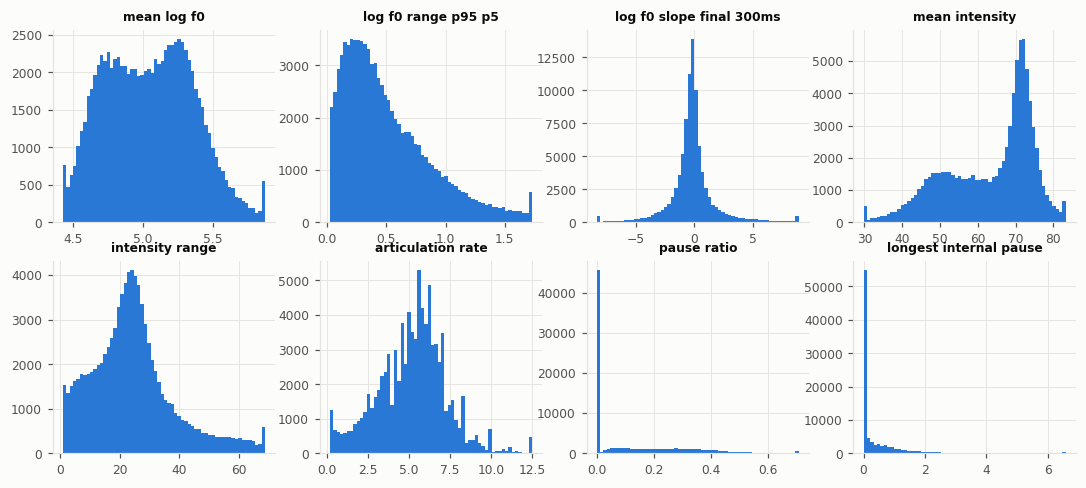

pitch_level_span


,mean_log_f0,log_f0_range_p95_p5
mean_log_f0,1.00,0.15
log_f0_range_p95_p5,0.15,1.00


energy


,mean_intensity,intensity_range
mean_intensity,1.0,0.1
intensity_range,0.1,1.0


timing


,articulation_rate,pause_ratio,longest_internal_pause
articulation_rate,1.00,0.15,0.04
pause_ratio,0.15,1.00,0.65
longest_internal_pause,0.04,0.65,1.00


In [8]:
import matplotlib.pyplot as plt
from src.config import TARGET_BLOCKS, TARGET_DIMENSIONS
from src.viz import style
style.apply()
ok = pro[pro['usable']]
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, d in zip(axes.ravel(), TARGET_DIMENSIONS):
    ax.hist(ok[d].clip(ok[d].quantile(0.005), ok[d].quantile(0.995)), bins=60, color=style.SERIES[0])
    ax.set_title(d.replace('_', ' '), fontsize=8)
style.save(fig, P.figures, f'08_prosody__{tag(STAGE, SETTINGS)}', 'distributions')
plt.show()
for b, ds in TARGET_BLOCKS.items():
    if len(ds) > 1:
        print(b); display(ok[list(ds)].corr().round(2))

**Reading it (exploratory).** The histograms show each dimension's raw, unstandardised distribution over usable turns; per-speaker standardisation in notebook 10 removes speaker level. The correlation tables show why within-block orthogonalisation is needed: correlated dimensions inside a block would otherwise be counted twice by block partial R². Nothing here relates a partner turn to its reply.